In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import precision_score,recall_score,accuracy_score,confusion_matrix
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras

In [23]:
df=pd.read_csv('Churn_Modelling.csv')

In [24]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [25]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [27]:
df["Geography"].unique()

array(['France', 'Spain', 'Germany'], dtype=object)

In [28]:
df['Surname'].unique()

array(['Hargrave', 'Hill', 'Onio', ..., 'Kashiwagi', 'Aldridge',
       'Burbidge'], shape=(2932,), dtype=object)

In [29]:
df['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [30]:
le=LabelEncoder()
df["Gender_encoded"]=le.fit_transform(df["Gender"])
df["Geogrpahy_encoded"]=le.fit_transform(df["Geography"])

In [31]:
df.drop(columns=['Gender','Geography','Surname','RowNumber','CustomerId'],inplace=True)

In [32]:
X=df.drop(columns=['Exited'])
Y=df['Exited']
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,random_state=42,test_size=0.2)

In [33]:
tf.random.set_seed(3)

In [34]:
X.columns

Index(['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Gender_encoded',
       'Geogrpahy_encoded'],
      dtype='object')

In [35]:
model1=keras.Sequential([
    keras.layers.Flatten(input_shape=(10,)),
    keras.layers.Dense(5,activation='relu'),
    keras.layers.Dense(2,activation='sigmoid')
])

C:\Users\fishb\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [36]:
model1.compile(optimizer='adam',
             loss='sparse_categorical_crossentropy',
              metrics=['accuracy']
)

In [37]:
history=model1.fit(X_train,Y_train,validation_split=0.1,epochs=10)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7113 - loss: 19368.9375 - val_accuracy: 0.8012 - val_loss: 8439.4844
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7932 - loss: 2323.5869 - val_accuracy: 0.8037 - val_loss: 79.2687
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7933 - loss: 44.0811 - val_accuracy: 0.8037 - val_loss: 13.6177
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7928 - loss: 11.6645 - val_accuracy: 0.8037 - val_loss: 5.0366
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7936 - loss: 6.1573 - val_accuracy: 0.8037 - val_loss: 5.6768
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7936 - loss: 5.8938 - val_accuracy: 0.8037 - val_loss: 1.2066
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7935 - loss: 5.3771 - val_accuracy: 0.8037 - val_loss: 1.0349
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7935 - loss: 5.8677 - va

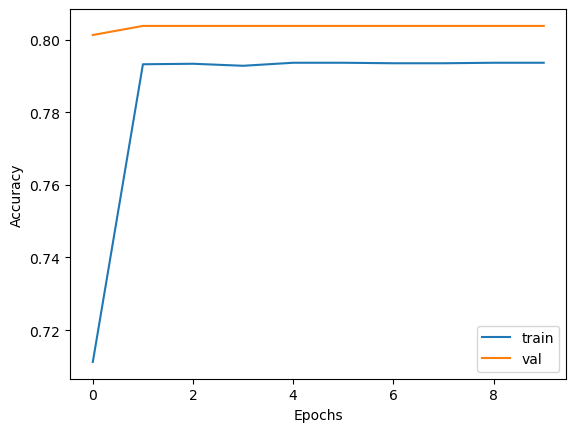

In [38]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train','val'],loc='lower right')
plt.show()

In [39]:
sc=StandardScaler()
X_train_std=sc.fit_transform(X_train)
X_test_std=sc.transform(X_test)
X_train_std

array([[ 0.35649971, -0.6557859 ,  0.34567966, ...,  1.36766974,
         0.91324755, -0.9055496 ],
       [-0.20389777,  0.29493847, -0.3483691 , ...,  1.6612541 ,
         0.91324755,  0.30164867],
       [-0.96147213, -1.41636539, -0.69539349, ..., -0.25280688,
         0.91324755,  1.50884694],
       ...,
       [ 0.86500853, -0.08535128, -1.38944225, ..., -0.1427649 ,
        -1.09499335, -0.9055496 ],
       [ 0.15932282,  0.3900109 ,  1.03972843, ..., -0.05082558,
         0.91324755, -0.9055496 ],
       [ 0.47065475,  1.15059039, -1.38944225, ..., -0.81456811,
         0.91324755,  0.30164867]], shape=(8000, 10))

In [40]:
model2=keras.Sequential([
    keras.layers.Flatten(input_shape=(10,)),
    keras.layers.Dense(30,activation='relu'),
    keras.layers.Dense(20,activation='relu'),
    keras.layers.Dense(10,activation='relu'),
    keras.layers.Dense(5,activation='relu'),
    keras.layers.Dense(2,activation='sigmoid')
])

C:\Users\fishb\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [41]:
model2.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
               metrics=['accuracy'],
              )

In [42]:
history=model2.fit(X_train_std,Y_train,validation_split=0.1,epochs=20)

Epoch 1/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7837 - loss: 0.5063 - val_accuracy: 0.8037 - val_loss: 0.4307
Epoch 2/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7960 - loss: 0.4321 - val_accuracy: 0.8075 - val_loss: 0.3969
Epoch 3/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8150 - loss: 0.3993 - val_accuracy: 0.8350 - val_loss: 0.3666
Epoch 4/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8413 - loss: 0.3745 - val_accuracy: 0.8512 - val_loss: 0.3581
Epoch 5/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8487 - loss: 0.3639 - val_accuracy: 0.8537 - val_loss: 0.3516
Epoch 6/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8519 - loss: 0.3564 - val_accuracy: 0.8575 - val_loss: 0.3465
Epoch 7/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8551 - loss: 0.3506 - val_accuracy: 0.8575 - val_loss: 0.3456
Epoch 8/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8562 - loss: 0.3462 - val_accuracy: 0.

In [43]:
loss,accuracy=model2.evaluate(X_test_std,Y_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8565 - loss: 0.3497  


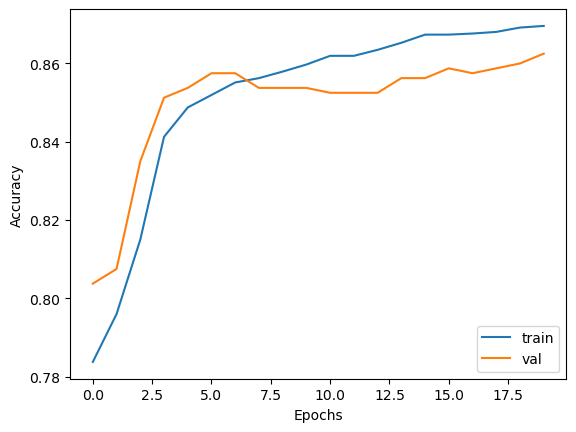

In [44]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train','val'],loc='lower right')
plt.show()

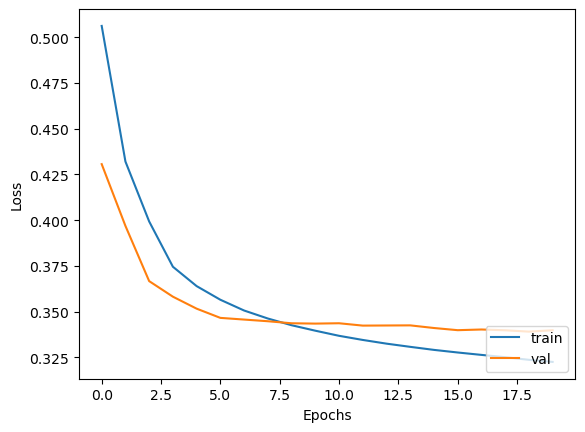

In [45]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train','val'],loc='lower right')
plt.show()

In [46]:
Y_pred=model2.predict(X_test_std)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  


In [47]:
Y_pred = Y_pred.argmax(axis=1)
cf=confusion_matrix(Y_pred,Y_test)
print("Confusion Matrix : \n",cf)
print("Accuracy : ",accuracy_score(Y_test,Y_pred))

Confusion Matrix : 
 [[1558  238]
 [  49  155]]
Accuracy :  0.8565
